# Tech Check 2 — Practice Notebook
## SQL DML + Jupyter + Pandas + Matplotlib

Built from the request in `notebook-requests/Topics include.md`. It works through every listed topic, in order, on a **new non-sakila relational database** created for this notebook.

**Topics covered**

1. SQL DML on a new relational database (given its ERD): `INSERT`, `UPDATE`, `DELETE`
2. SQL queries that retrieve result sets: one or more tables, grouping, aggregation functions, ordering, limiting
3. Jupyter Notebook structure with markdown
4. Importing the usual libraries plus the library for interacting with SQL (`psycopg2`)
5. Installing the pip packages needed to interact with SQL
6. Loading data into a Pandas DataFrame from a SQL query
7. Basic calculations and manipulation of the DataFrame in Pandas
8. Charting the resulting data with Matplotlib

**The sample database — a small bookstore.** ERD in words:

- `authors(author_id PK, author_name, country)` — one author writes many books
- `books(book_id PK, title, author_id FK -> authors, genre, price, stock)` — each book belongs to one author
- `customers(customer_id PK, full_name, email, city)` — one customer places many orders
- `orders(order_id PK, customer_id FK -> customers, book_id FK -> books, quantity, order_date)` — each order is one customer buying some copies of one book

## 1. Setup — install the SQL package

`psycopg2` is the library Python uses to talk to PostgreSQL. In a notebook you install it once with pip (the `!pip install psycopg2-binary` shell form does the same thing).

In [1]:
import subprocess
import sys

# Install the PostgreSQL driver (safe to re-run: pip skips it if already present).
subprocess.check_call([sys.executable, "-m", "pip", "install", "psycopg2-binary"])
print("psycopg2-binary is installed")

psycopg2-binary is installed


## 2. Import the usual libraries, plus the SQL library

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import psycopg2

print("pandas", pd.__version__)
print("psycopg2", psycopg2.__version__)

pandas 3.1.0
psycopg2 2.9.13 (dt dec pq3 ext lo64)


## 3. Connect to PostgreSQL

In the course Codespace the pattern is `host="localhost"`, `user="postgres"`, `password="postgres"`. This practice copy takes its connection string from the `PG_TEST_URI` environment variable when one is set, with a local practice server as the default.

In [3]:
import os

PG_URI = os.environ.get(
    "PG_TEST_URI",
    "postgresql://postgres@/tc2_practice?host=/home/pguser/sock&port=5433",
)
conn = psycopg2.connect(PG_URI)
cur = conn.cursor()

cur.execute("SELECT version();")
print(cur.fetchone()[0])

PostgreSQL 18.6 on x86_64-pc-linux-gnu, compiled by gcc (Debian 12.2.0-14+deb12u1) 12.2.0, 64-bit


## 4. Create the tables from the ERD

A small amount of DDL first, so the DML below has a database to work on. `DROP TABLE IF EXISTS` makes the notebook safe to re-run from the top.

In [4]:
cur.execute(
    """
    DROP TABLE IF EXISTS orders;
    DROP TABLE IF EXISTS books;
    DROP TABLE IF EXISTS customers;
    DROP TABLE IF EXISTS authors;

    CREATE TABLE authors (
        author_id   INTEGER PRIMARY KEY,
        author_name VARCHAR(100) NOT NULL,
        country     VARCHAR(60)
    );

    CREATE TABLE books (
        book_id   INTEGER PRIMARY KEY,
        title     VARCHAR(150) NOT NULL,
        author_id INTEGER NOT NULL REFERENCES authors(author_id),
        genre     VARCHAR(40),
        price     NUMERIC(8, 2) NOT NULL,
        stock     INTEGER NOT NULL DEFAULT 0
    );

    CREATE TABLE customers (
        customer_id INTEGER PRIMARY KEY,
        full_name   VARCHAR(100) NOT NULL,
        email       VARCHAR(120),
        city        VARCHAR(60)
    );

    CREATE TABLE orders (
        order_id    INTEGER PRIMARY KEY,
        customer_id INTEGER NOT NULL REFERENCES customers(customer_id),
        book_id     INTEGER NOT NULL REFERENCES books(book_id),
        quantity    INTEGER NOT NULL CHECK (quantity > 0),
        order_date  DATE NOT NULL
    );
    """
)
conn.commit()
print("Tables created: authors, books, customers, orders")

Tables created: authors, books, customers, orders


## 5. DML — INSERT records

Parent tables first (`authors`, `customers`), then the tables that reference them (`books`, `orders`) — foreign keys require the referenced row to exist already.

In [5]:
cur.execute(
    """
    INSERT INTO authors (author_id, author_name, country) VALUES
        (1, 'Margaret Atwood', 'Canada'),
        (2, 'Yann Martel', 'Canada'),
        (3, 'Agatha Christie', 'United Kingdom'),
        (4, 'Haruki Murakami', 'Japan');

    INSERT INTO books (book_id, title, author_id, genre, price, stock) VALUES
        (1, 'The Handmaid''s Tale', 1, 'Fiction', 18.99, 25),
        (2, 'Life of Pi', 2, 'Fiction', 16.50, 30),
        (3, 'Murder on the Orient Express', 3, 'Mystery', 12.99, 40),
        (4, 'And Then There Were None', 3, 'Mystery', 11.99, 35),
        (5, 'Norwegian Wood', 4, 'Fiction', 15.99, 20),
        (6, 'The Murder of Roger Ackroyd', 3, 'Mystery', 10.99, 15),
        (7, 'Death on the Nile', 3, 'Mystery', 13.99, 10);

    INSERT INTO customers (customer_id, full_name, email, city) VALUES
        (1, 'Emma Tremblay', 'emma@example.com', 'Halifax'),
        (2, 'Liam O''Neil', 'liam@example.com', 'Dartmouth'),
        (3, 'Sofia Roy', 'sofia@example.com', 'Halifax'),
        (4, 'Noah Smith', 'noah@example.com', 'Bedford');

    INSERT INTO orders (order_id, customer_id, book_id, quantity, order_date) VALUES
        (1, 1, 3, 2, '2026-10-01'),
        (2, 1, 1, 1, '2026-10-02'),
        (3, 2, 2, 3, '2026-10-03'),
        (4, 3, 3, 1, '2026-10-05'),
        (5, 3, 4, 2, '2026-10-06'),
        (6, 4, 5, 1, '2026-10-07'),
        (7, 2, 6, 4, '2026-10-08'),
        (8, 1, 4, 1, '2026-10-09');
    """
)
conn.commit()

for table in ("authors", "books", "customers", "orders"):
    cur.execute(f"SELECT COUNT(*) FROM {table};")
    print(table, "rows:", cur.fetchone()[0])

authors rows: 4
books rows: 7
customers rows: 4
orders rows: 8


## 6. DML — UPDATE records

Two typical updates: a price change for one genre only (note the `WHERE` — without it, **every** row changes), and a stock adjustment after a sale.

In [6]:
# Raise every Mystery price by 10%, rounded to cents.
cur.execute(
    "UPDATE books SET price = ROUND(price * 1.10, 2) WHERE genre = 'Mystery';"
)
print("Prices updated:", cur.rowcount)

# Book 3 sold 3 more copies than expected: take them out of stock.
cur.execute("UPDATE books SET stock = stock - 3 WHERE book_id = 3;")
print("Stock updated:", cur.rowcount)
conn.commit()

cur.execute("SELECT book_id, title, genre, price, stock FROM books ORDER BY book_id;")
for row in cur.fetchall():
    print(row)

Prices updated: 4
Stock updated: 1
(1, "The Handmaid's Tale", 'Fiction', Decimal('18.99'), 25)
(2, 'Life of Pi', 'Fiction', Decimal('16.50'), 30)
(3, 'Murder on the Orient Express', 'Mystery', Decimal('14.29'), 37)
(4, 'And Then There Were None', 'Mystery', Decimal('13.19'), 35)
(5, 'Norwegian Wood', 'Fiction', Decimal('15.99'), 20)
(6, 'The Murder of Roger Ackroyd', 'Mystery', Decimal('12.09'), 15)
(7, 'Death on the Nile', 'Mystery', Decimal('15.39'), 10)


## 7. DML — DELETE records

Two cases: a cancelled order is removed, and a discontinued book can be deleted **because no order references it** — the foreign key on `orders.book_id` would block deleting a book that has orders.

In [7]:
# A customer places an order, then cancels it.
cur.execute(
    "INSERT INTO orders (order_id, customer_id, book_id, quantity, order_date) "
    "VALUES (9, 4, 2, 1, '2026-10-10');"
)
conn.commit()
cur.execute("SELECT COUNT(*) FROM orders;")
print("Orders after insert:", cur.fetchone()[0])

cur.execute("DELETE FROM orders WHERE order_id = 9;")
print("Orders deleted:", cur.rowcount)
conn.commit()
cur.execute("SELECT COUNT(*) FROM orders;")
print("Orders after delete:", cur.fetchone()[0])

# Book 7 was never ordered, so it can be removed.
cur.execute("DELETE FROM books WHERE book_id = 7;")
print("Books deleted:", cur.rowcount)
conn.commit()

Orders after insert: 9
Orders deleted: 1
Orders after delete: 8
Books deleted: 1


## 8. Query 1 — one table, with WHERE, ORDER BY and LIMIT

The three cheapest books under $15, most expensive of the three first.

In [8]:
cur.execute(
    """
    SELECT title, genre, price
    FROM books
    WHERE price < 15
    ORDER BY price DESC
    LIMIT 3;
    """
)
for row in cur.fetchall():
    print(row)

('Murder on the Orient Express', 'Mystery', Decimal('14.29'))
('And Then There Were None', 'Mystery', Decimal('13.19'))
('The Murder of Roger Ackroyd', 'Mystery', Decimal('12.09'))


## 9. Query 2 — JOIN across three tables

Every order, showing the customer's name and the book title instead of bare ID numbers, with the line total calculated in SQL.

In [9]:
cur.execute(
    """
    SELECT o.order_id, c.full_name, b.title, o.quantity, b.price,
           o.quantity * b.price AS line_total
    FROM orders o
    JOIN customers c ON c.customer_id = o.customer_id
    JOIN books b     ON b.book_id = o.book_id
    ORDER BY o.order_id;
    """
)
for row in cur.fetchall():
    print(row)

(1, 'Emma Tremblay', 'Murder on the Orient Express', 2, Decimal('14.29'), Decimal('28.58'))
(2, 'Emma Tremblay', "The Handmaid's Tale", 1, Decimal('18.99'), Decimal('18.99'))
(3, "Liam O'Neil", 'Life of Pi', 3, Decimal('16.50'), Decimal('49.50'))
(4, 'Sofia Roy', 'Murder on the Orient Express', 1, Decimal('14.29'), Decimal('14.29'))
(5, 'Sofia Roy', 'And Then There Were None', 2, Decimal('13.19'), Decimal('26.38'))
(6, 'Noah Smith', 'Norwegian Wood', 1, Decimal('15.99'), Decimal('15.99'))
(7, "Liam O'Neil", 'The Murder of Roger Ackroyd', 4, Decimal('12.09'), Decimal('48.36'))
(8, 'Emma Tremblay', 'And Then There Were None', 1, Decimal('13.19'), Decimal('13.19'))


## 10. Query 3 — GROUP BY with aggregation functions and HAVING

Units sold and revenue per genre. `HAVING` filters **after** grouping (it filters the aggregates, where `WHERE` filters rows before grouping).

In [10]:
cur.execute(
    """
    SELECT b.genre,
           COUNT(*)              AS order_lines,
           SUM(o.quantity)       AS units_sold,
           SUM(o.quantity * b.price) AS revenue
    FROM orders o
    JOIN books b ON b.book_id = o.book_id
    GROUP BY b.genre
    HAVING SUM(o.quantity) > 4
    ORDER BY revenue DESC;
    """
)
for row in cur.fetchall():
    print(row)

('Mystery', 5, 10, Decimal('130.80'))
('Fiction', 3, 5, Decimal('84.48'))


## 11. Query 4 — Top 3 customers by total spent

Grouping + aggregation + ordering + limiting in one query: aggregate per customer, sort by the aggregate, keep the top 3.

In [11]:
cur.execute(
    """
    SELECT c.full_name,
           COUNT(*)                  AS orders_placed,
           SUM(o.quantity * b.price) AS total_spent
    FROM orders o
    JOIN customers c ON c.customer_id = o.customer_id
    JOIN books b     ON b.book_id = o.book_id
    GROUP BY c.full_name
    ORDER BY total_spent DESC
    LIMIT 3;
    """
)
for row in cur.fetchall():
    print(row)

("Liam O'Neil", 2, Decimal('97.86'))
('Emma Tremblay', 3, Decimal('60.76'))
('Sofia Roy', 2, Decimal('40.67'))


## 12. Pandas — load a SQL query into a DataFrame

`pd.read_sql_query` runs the query through the same connection and returns a DataFrame. (The UserWarning about SQLAlchemy is expected with a psycopg2 connection and is harmless for this exercise.) The genre revenue query from section 10 becomes the DataFrame used for the chart.

In [12]:
genre_df = pd.read_sql_query(
    """
    SELECT b.genre,
           SUM(o.quantity)           AS units_sold,
           SUM(o.quantity * b.price) AS revenue
    FROM orders o
    JOIN books b ON b.book_id = o.book_id
    GROUP BY b.genre
    ORDER BY revenue DESC;
    """,
    conn,
)
print(genre_df)
print(genre_df.dtypes)

     genre  units_sold  revenue
0  Mystery          10   130.80
1  Fiction           5    84.48
genre             str
units_sold      int64
revenue       float64
dtype: object


<cell 12>:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.


## 13. Pandas — basic calculations and manipulation

Load the order detail, add a calculated column, aggregate with Pandas this time (compare with the SQL in section 11), and filter rows.

In [13]:
orders_df = pd.read_sql_query(
    """
    SELECT o.order_id, c.full_name, b.title, b.genre, o.quantity, b.price
    FROM orders o
    JOIN customers c ON c.customer_id = o.customer_id
    JOIN books b     ON b.book_id = o.book_id
    ORDER BY o.order_id;
    """,
    conn,
)

# New calculated column.
orders_df["line_total"] = orders_df["quantity"] * orders_df["price"]
print(orders_df)

# Total spent per customer, biggest first (same answer as the SQL in section 11).
totals = orders_df.groupby("full_name")["line_total"].sum().sort_values(ascending=False)
print("\nTotal spent per customer:")
print(totals)

# Filter: only the larger orders.
print("\nOrders with a line total of $30 or more:")
print(orders_df[orders_df["line_total"] >= 30])

   order_id      full_name  ...  price  line_total
0         1  Emma Tremblay  ...  14.29       28.58
1         2  Emma Tremblay  ...  18.99       18.99
2         3    Liam O'Neil  ...  16.50       49.50
3         4      Sofia Roy  ...  14.29       14.29
4         5      Sofia Roy  ...  13.19       26.38
5         6     Noah Smith  ...  15.99       15.99
6         7    Liam O'Neil  ...  12.09       48.36
7         8  Emma Tremblay  ...  13.19       13.19

[8 rows x 7 columns]

Total spent per customer:
full_name
Liam O'Neil      97.86
Emma Tremblay    60.76
Sofia Roy        40.67
Noah Smith       15.99
Name: line_total, dtype: float64

Orders with a line total of $30 or more:
   order_id    full_name  ...  price  line_total
2         3  Liam O'Neil  ...  16.50       49.50
6         7  Liam O'Neil  ...  12.09       48.36

[2 rows x 7 columns]


<cell 13>:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.


## 14. Matplotlib — chart the resulting data

Revenue by genre, from the DataFrame loaded in section 12.

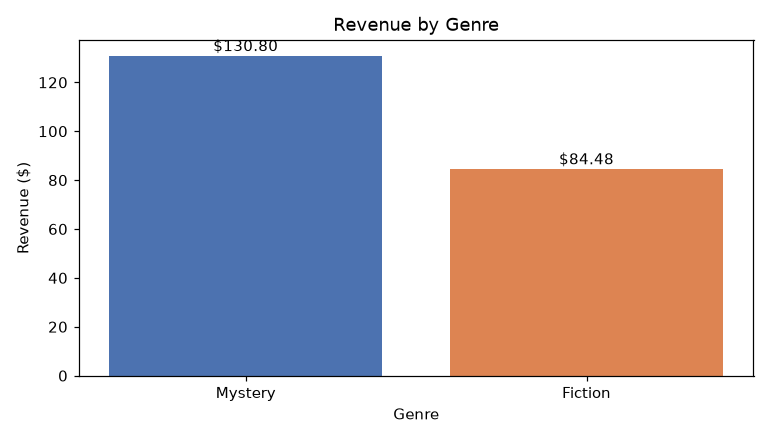

In [14]:
plt.figure(figsize=(7, 4))
plt.bar(genre_df["genre"], genre_df["revenue"], color=["#4C72B0", "#DD8452"])
plt.title("Revenue by Genre")
plt.xlabel("Genre")
plt.ylabel("Revenue ($)")
for i, v in enumerate(genre_df["revenue"]):
    plt.text(i, float(v) + 2, f"${float(v):.2f}", ha="center")
plt.tight_layout()
plt.show()

## Wrap-up — topic checklist

- [x] DML `INSERT` / `UPDATE` / `DELETE` on a new non-sakila database (sections 5–7)
- [x] Retrieval queries: single table, JOINs, `GROUP BY` + aggregation, `HAVING`, `ORDER BY`, `LIMIT` (sections 8–11)
- [x] Jupyter Notebook with markdown structure (this notebook)
- [x] Usual libraries imported, plus `psycopg2` for SQL (section 2)
- [x] pip install of the SQL package (section 1)
- [x] SQL query loaded into a Pandas DataFrame (section 12)
- [x] DataFrame calculations and manipulation (section 13)
- [x] Matplotlib chart of the results (section 14)

In [15]:
cur.close()
conn.close()
print("Connection closed.")

Connection closed.
